# 선석점유율

선석 점유율 = Σ 작업시간 ÷ (선석 수 × 기간 시간) × 100

In [1]:
# 작업시간 = 재항시간-추정대기시간
# 추정대기시간 = max(0,이전 배 출항 - 현재 배 입항)



In [2]:
import pandas as pd

df = pd.read_csv(
    "../data/record.csv",
    encoding="utf-8-sig"
)

print(df.head())

    호출부호              선명    입항횟수      총톤수                 입항일시  \
0  3FRF8     SONG YUN HE  2022.0   16,737  2022-01-01 00:48:00   
1  VRNA9  SEASPAN THAMES  2022.0  112,967  2022-01-01 02:00:00   
2  VRRP8  CMA CGM MUMBAI  2022.0  112,967  2022-01-01 03:00:00   
3  D5TL4       MSC JEWEL  2022.0  140,976  2022-01-01 03:22:00   
4  A8YT7        MALIAKOS  2022.0   41,391  2022-01-01 03:35:00   

                  출항일시           CIQ수속일자              수리일시       MRN 번호  \
0  2022-01-03 01:52:00   2022-01-03 1:52  2022-01-03 15:58  22COHES152E   
1  2022-01-02 17:43:00  2022-01-02 17:43  2022-01-03 11:18  22HLCU4202E   
2  2022-01-02 04:06:00   2022-01-02 4:00  2022-01-03 11:22  22CMAL0030E   
3  2022-01-03 05:00:00   2022-01-03 5:00  2022-01-03 11:19  22MSCU0004E   
4  2022-01-01 16:45:00  2022-01-01 16:00  2022-01-03 11:07  22SMLME016E   

         계선장소         차항지       전출항지       재항시간  
0  신항 5부두 3선석     QINGDAO         광양  49.066667  
1  신항 3부두 4선석   VANCOUVER   SHANGHAI  39.716667  
2 

# 부두별 월별 총 재항시간

             1부두      2부두      3부두      4부두      5부두
월                                                   
2022-01  2009.32  3137.90  2108.45  1565.63  2382.03
2022-02  1795.40  3282.37  2052.67  1628.72  2613.52
2022-03  1657.17  3412.95  1978.02  2117.52  2647.33
2022-04  1891.30  3473.43  2062.47  1935.43  2522.78
2022-05  1956.22  3505.60  2004.22  2053.75  2515.72
2022-06  1781.70  2945.57  2081.38  1385.87  2591.43
2022-07  1932.23  3512.15  1971.62  1508.43  2233.22
2022-08  1811.27  3240.58  1531.12  1674.38  2250.88
2022-09  1736.28  2788.80  1456.47  1310.55  2379.53
2022-10  1625.05  2781.85  1420.28  1588.43  2817.93
2022-11  1440.72  2971.58  1441.23  1504.07  2446.82
2022-12  1560.65  3095.22  1476.92  1367.60  2095.98
2023-01  1603.08  3325.28  1791.58  1703.48  2399.12
2023-02  1575.73  3276.38  1592.65  1678.78  2083.32
2023-03  2053.25  3623.95  1985.08  1716.20  2028.53
2023-04  1912.70  3521.73  1801.97  1737.38  1878.28
2023-05  1683.78  4071.00  1829.87  1917.33  2

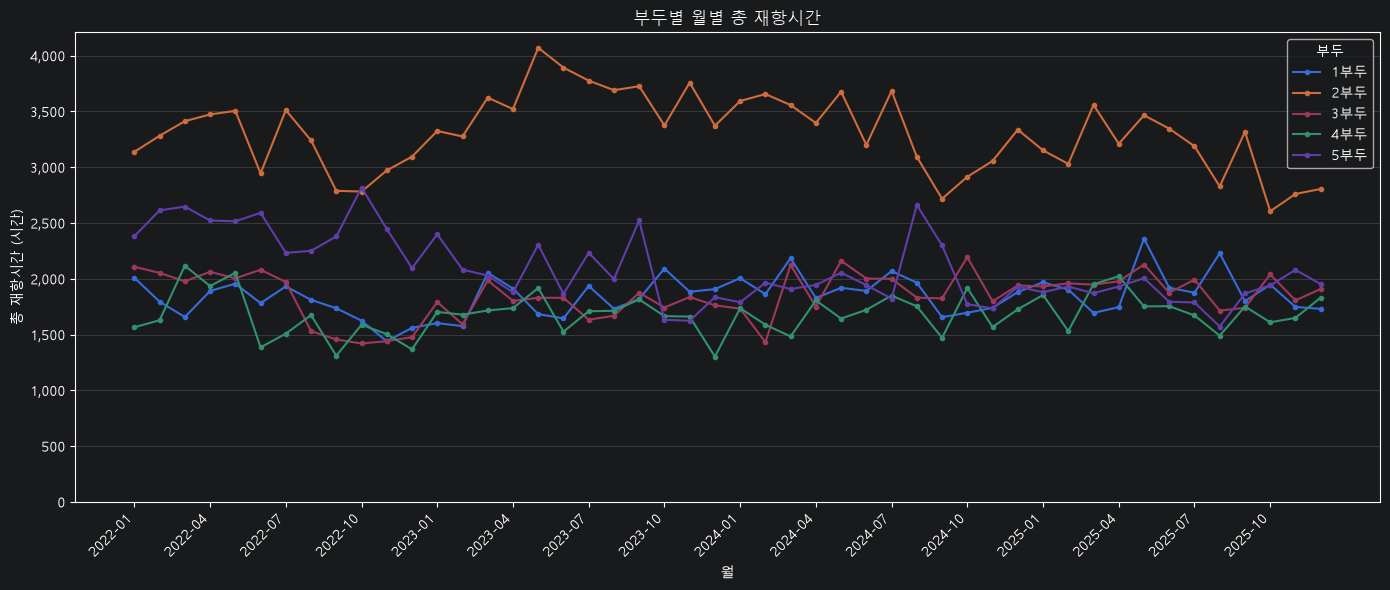

In [11]:
import pandas as pd

# CSV 파일을 파이썬 코드와 같은 폴더에 두세요.
df = pd.read_csv("../data/record.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()

for col in ["입항일시", "출항일시"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두", expand=False
)
df["재항시간"] = (
    df["출항일시"] - df["입항일시"]
).dt.total_seconds() / 3600

# 날짜 누락·변환 실패·음수 시간·대상 외 부두 제외
data = df.loc[
    df["재항시간"].ge(0) & df["부두"].notna()
].copy()

# 분석 기간: 종료 시각은 포함하지 않음
start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")

months = pd.date_range(start, end, freq="MS", inclusive="left")
result = pd.DataFrame(
    index=months, columns=list("12345"), dtype=float
)

for month in months:
    next_month = month + pd.offsets.MonthBegin(1)

    # 각 선박의 재항 구간 중 해당 월과 겹치는 시간
    hours = (
        data["출항일시"].clip(upper=next_month)
        - data["입항일시"].clip(lower=month)
    ).dt.total_seconds().div(3600).clip(lower=0)

    result.loc[month] = (
        hours.groupby(data["부두"]).sum()
        .reindex(list("12345"), fill_value=0)
    )

result.index = result.index.strftime("%Y-%m")
result.index.name = "월"
result.columns = result.columns + "부두"

print(result.round(2).to_string())

# 월별·부두별 추이 그래프
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ax = result.plot(figsize=(14, 6), marker="o", markersize=3)
ax.set_title("부두별 월별 총 재항시간")
ax.set_xlabel("월")
ax.set_ylabel("총 재항시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두")
plt.xticks(rotation=45)
# 분기마다 날짜 표시
ticks = list(range(0, len(result), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    result.index[ticks],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

# 부두별 월별 총 추정대기 시간

전체 기록: 19,989건
제외 기록: 0건

부두별·월별 총 추정대기시간 (시간)
            1부두     2부두     3부두     4부두     5부두
월                                              
2022-01  171.93  225.40  242.87  207.78  416.87
2022-02   55.60  440.08  496.08  234.45  716.02
2022-03   30.27  375.68   70.52  362.88  729.95
2022-04   97.67  450.23  195.17  304.57  598.43
2022-05  140.28  397.85  265.48  437.93  666.72
2022-06   64.58  198.35  384.80   95.85  465.25
2022-07   21.18  413.05  192.43  119.77  271.90
2022-08   39.80  377.00   32.83  107.43  314.07
2022-09  168.55  370.12   60.17   74.20  755.87
2022-10   54.38  112.15   34.82   49.40  791.97
2022-11   30.20  196.62   44.38   20.40  416.48
2022-12   89.62  129.40   82.78   26.85  362.53
2023-01   14.15  262.60   83.10   70.57  379.88
2023-02    0.00  396.68  112.38  149.25  452.55
2023-03  129.10  259.82  247.77   26.52   69.12
2023-04  130.35  320.10  125.60   81.88   98.43
2023-05   56.23  751.82  181.27  152.13  325.67
2023-06  132.98  725.97  131.75  148.90  

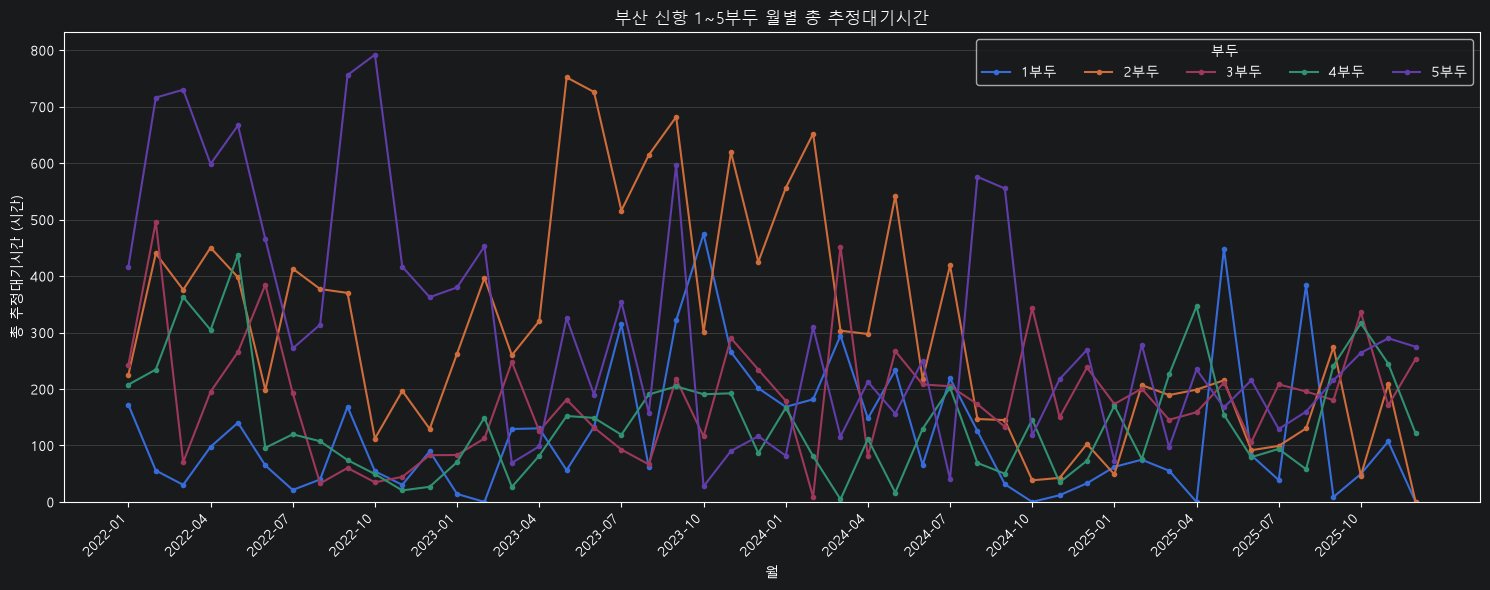

In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# ── 1. 설정 ─────────────────────────────────────
DATA_PATH = Path(
    r"C:\work\Final_Project\Final_Project\data\record.csv"
)

# 분석 기간: 2022~2025년, 종료 시각은 포함하지 않음
START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ── 2. CSV 불러오기 ─────────────────────────────
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

# 부두·선석 추출: 예) 신항 1부두 2선석
df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

# 장소·날짜 누락 및 출항이 입항보다 빠른 기록 제외
valid = (
    df[["부두", "선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
)

print(f"전체 기록: {len(df):,}건")
print(f"제외 기록: {(~valid).sum():,}건")

df = df.loc[valid].copy()

# ── 3. 선박별 추정대기시간 ──────────────────────
# 기간 경계 이전 선박도 비교해야 하므로 아직 기간 필터를 적용하지 않음
df = df.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

# 같은 선석에서 입항 순서상 직전 선박의 출항 시각
df["앞배_출항"] = (
    df.groupby(["부두", "선석"])["출항"].shift()
)

# 직전 선박 출항 - 현재 선박 입항
# 음수 및 각 선석의 첫 기록은 0시간
df["추정대기"] = (
    (df["앞배_출항"] - df["입항"])
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
    .fillna(0)
)

# 추정대기 구간
df["대기시작"] = df["입항"]
df["대기종료"] = (
    df["입항"]
    + pd.to_timedelta(df["추정대기"], unit="h")
)

# ── 4. 부두별·월별 집계 ─────────────────────────
months = pd.date_range(
    START, END, freq="MS", inclusive="left"
)

result = pd.DataFrame(
    index=months,
    columns=list("12345"),
    dtype=float
)

for month in months:
    next_month = month + pd.offsets.MonthBegin(1)

    # 추정대기 구간 중 해당 월과 겹치는 시간만 계산
    # 예: 1월 31일 23시~2월 1일 02시 → 1월 1시간, 2월 2시간
    monthly_hours = (
        df["대기종료"].clip(upper=next_month)
        - df["대기시작"].clip(lower=month)
    ).dt.total_seconds().div(3600).clip(lower=0)

    result.loc[month] = (
        monthly_hours.groupby(df["부두"])
        .sum()
        .reindex(list("12345"), fill_value=0)
    )

result.index = result.index.strftime("%Y-%m")
result.index.name = "월"
result.columns = result.columns + "부두"

print("\n부두별·월별 총 추정대기시간 (시간)")
print(result.round(2).to_string())

print("\n분석 기간 내 부두별 합계 (시간)")
print(result.sum().round(2).to_string())

# ── 5. 그래프 ───────────────────────────────────
fig, ax = plt.subplots(figsize=(15, 6))

for terminal in result.columns:
    ax.plot(
        result.index,
        result[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

ax.set_title("부산 신항 1~5부두 월별 총 추정대기시간")
ax.set_xlabel("월")
ax.set_ylabel("총 추정대기시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)

# 분기별 날짜 표시: 매년 1·4·7·10월
ticks = list(range(0, len(result), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    result.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두", ncol=5)

plt.tight_layout()
plt.show()

# 부두별 월별 총 작업시간 (총재항시간-총추정대기시간)

In [5]:
result = (
    df.groupby("부두")[["재항시간", "추정대기"]]
    .sum()
    .reindex(list("12345"), fill_value=0)
)

result.columns = ["총 재항시간", "총 추정대기시간"]
result["작업시간"] = result["총 재항시간"] - result["총 추정대기시간"]
result.index = result.index + "부두"

print(result.round(2).to_string())

        총 재항시간  총 추정대기시간       작업시간
부두                                 
1부두   88682.35   5889.05   82793.30
2부두  158771.60  14732.18  144039.42
3부두   88756.00   8779.27   79976.73
4부두   80988.10   6866.35   74121.75
5부두  100373.73  14665.58   85708.15


부두별·월별 총 추정작업시간 (시간)
부두           1부두      2부두      3부두      4부두      5부두
월                                                   
2022-01  1837.38  2912.50  1865.58  1357.85  1965.17
2022-02  1739.80  2842.28  1556.58  1394.27  1897.50
2022-03  1626.90  3037.27  1907.50  1754.63  1917.38
2022-04  1793.63  3023.20  1867.30  1630.87  1924.35
2022-05  1815.93  3107.75  1738.73  1615.82  1849.00
2022-06  1717.12  2747.22  1696.58  1290.02  2126.18
2022-07  1911.05  3099.10  1779.18  1388.67  1961.32
2022-08  1771.47  2863.58  1498.28  1566.95  1936.82
2022-09  1567.73  2418.68  1396.30  1236.35  1623.67
2022-10  1570.67  2669.70  1385.47  1539.03  2025.97
2022-11  1410.52  2774.97  1396.85  1483.67  2030.33
2022-12  1471.03  2965.82  1394.13  1340.75  1733.45
2023-01  1588.93  3062.68  1708.48  1632.92  2019.23
2023-02  1575.73  2879.70  1480.27  1529.53  1630.77
2023-03  1924.15  3364.13  1737.32  1689.68  1959.42
2023-04  1782.35  3201.63  1676.37  1655.50  1779.85
2023-05  1627.55  3319.18

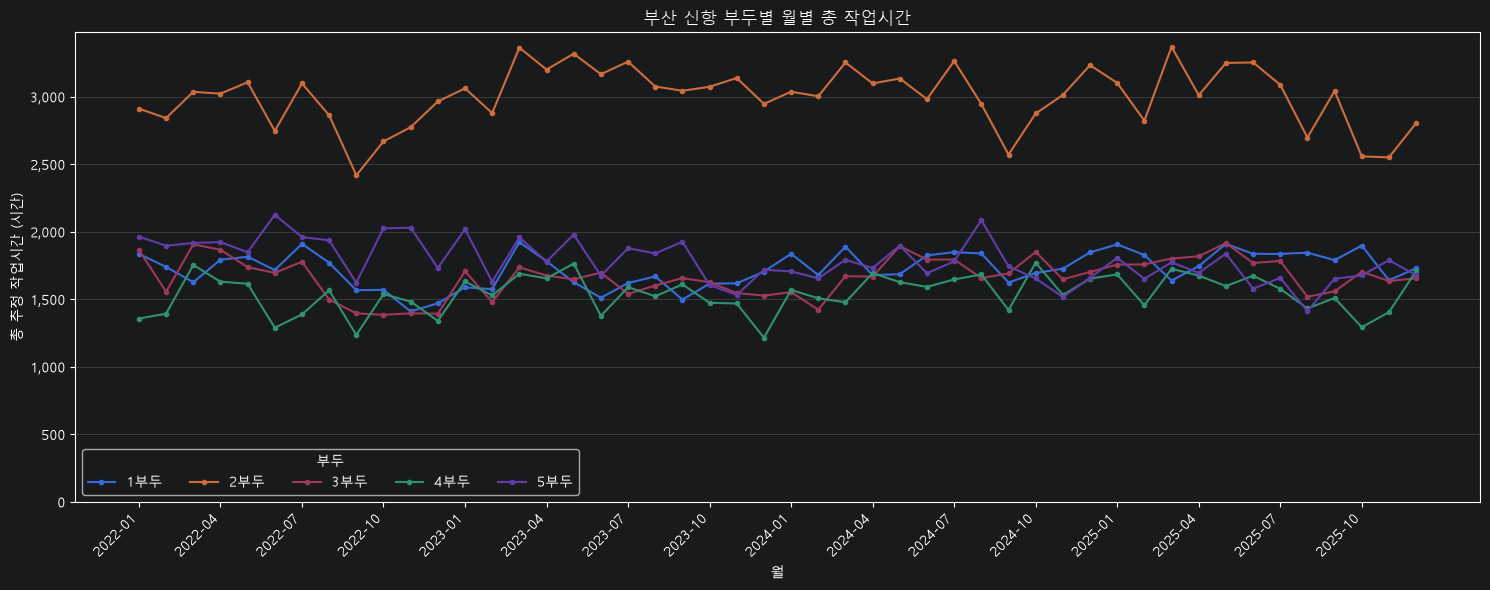

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 1. 월별·부두별 총 작업시간 계산
work_data = occupancy.copy()

work_data["총 작업시간"] = (
    work_data["총 재항시간"]
    - work_data["총 추정대기시간"]
)

# 행: 월 / 열: 부두 / 값: 총 작업시간
monthly_work = (
    work_data.pivot(
        index="월",
        columns="부두",
        values="총 작업시간"
    )
    .sort_index()
    .reindex(columns=["1부두", "2부두", "3부두", "4부두", "5부두"])
)

print("부두별·월별 총 추정작업시간 (시간)")
print(monthly_work.round(2).to_string())

# 2. 라인그래프
fig, ax = plt.subplots(figsize=(15, 6))

for terminal in monthly_work.columns:
    ax.plot(
        monthly_work.index,
        monthly_work[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

# 분기 간격: 매년 1·4·7·10월 표시
ticks = list(range(0, len(monthly_work), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    monthly_work.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_title("부산 신항 부두별 월별 총 작업시간")
ax.set_xlabel("월")
ax.set_ylabel("총 추정 작업시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# 음수 결과가 있다면 숨기지 않고 표시
if monthly_work.min().min() >= 0:
    ax.set_ylim(bottom=0)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두", ncol=5)

plt.tight_layout()
plt.show()

# 선석수

In [7]:
import pandas as pd

# 앞서 제공한 이미지 기준 선석 수
선석수 = {1: 3, 2: 6, 3: 4, 4: 4, 5: 4}

선석수표 = pd.DataFrame({
    "부두": list(선석수.keys()),
    "선석수": list(선석수.values())
})

print(선석수표.to_string(index=False))

 부두  선석수
  1    3
  2    6
  3    4
  4    4
  5    4


# 선석점유율

전체 기록: 19,989건
유효 기록: 19,989건
제외 기록: 0건
추정대기 종료가 본선 출항보다 늦은 기록: 782건

부두별·월별 상세 결과 — 시간 단위: 시간(h)
      월  부두  총 재항시간  총 추정대기시간  추정 작업시간  선석 수  기간 시간  가용 선석시간  추정 선석 점유율(%)
2022-01 1부두 2009.32    171.93  1837.38     3  744.0   2232.0         82.32
2022-01 2부두 3137.90    225.40  2912.50     6  744.0   4464.0         65.24
2022-01 3부두 2108.45    242.87  1865.58     4  744.0   2976.0         62.69
2022-01 4부두 1565.63    207.78  1357.85     4  744.0   2976.0         45.63
2022-01 5부두 2382.03    416.87  1965.17     4  744.0   2976.0         66.03
2022-02 1부두 1795.40     55.60  1739.80     3  672.0   2016.0         86.30
2022-02 2부두 3282.37    440.08  2842.28     6  672.0   4032.0         70.49
2022-02 3부두 2052.67    496.08  1556.58     4  672.0   2688.0         57.91
2022-02 4부두 1628.72    234.45  1394.27     4  672.0   2688.0         51.87
2022-02 5부두 2613.52    716.02  1897.50     4  672.0   2688.0         70.59
2022-03 1부두 1657.17     30.27  1626.90     3  744.0   2232.0         72.89
20

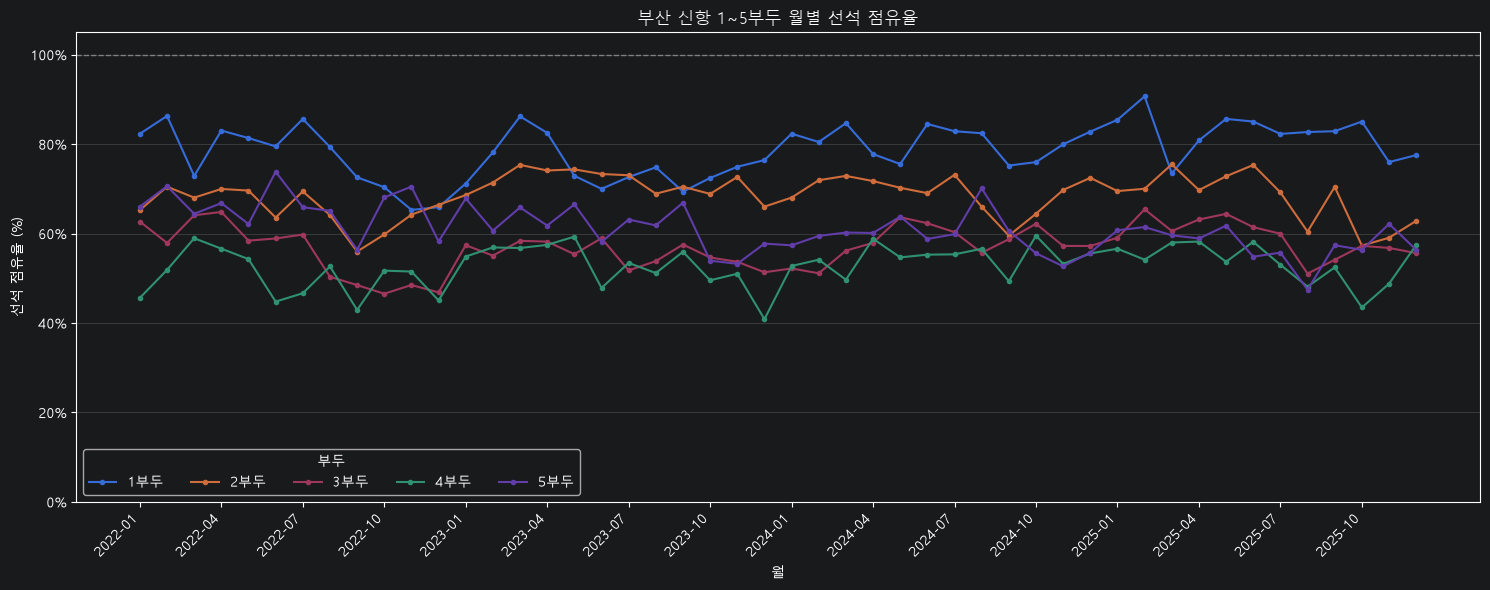

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ── 1. 데이터 및 분석 기간 설정 ─────────────────
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\record.csv"

# 2022~2025년 분석
# 2025년만 분석하려면 start를 "2025-01-01"로 변경
start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")  # 종료 시각 미포함

berth_counts = {
    "1": 3,
    "2": 6,
    "3": 4,
    "4": 4,
    "5": 4
}

# ── 2. CSV 불러오기 및 정리 ──────────────────────
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

# 장소·날짜 누락, 출항이 입항보다 빠른 기록 제외
valid = (
    df[["부두", "선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
)

data = df.loc[valid].copy()

print(f"전체 기록: {len(df):,}건")
print(f"유효 기록: {len(data):,}건")
print(f"제외 기록: {(~valid).sum():,}건")

# ── 3. 선박별 추정대기 구간 계산 ─────────────────
# 직전 선박 확인을 위해 분석 기간으로 먼저 필터링하지 않음
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 추정대기 = max(0, 직전 선박 출항 - 현재 선박 입항)
# 첫 기록은 앞배 출항이 없으므로 대기종료 = 입항
data["대기종료"] = data[["입항", "앞배_출항"]].max(axis=1)

data["추정대기시간"] = (
    data["대기종료"] - data["입항"]
).dt.total_seconds() / 3600

# 추정 방식의 이상 기록 확인
abnormal = data["대기종료"].gt(data["출항"])
print(
    "추정대기 종료가 본선 출항보다 늦은 기록:",
    f"{abnormal.sum():,}건"
)

# ── 4. 특정 월에 포함되는 시간 계산 함수 ─────────
def hours_in_month(begin, finish, month_start, month_end):
    """각 구간 중 해당 월과 겹치는 시간을 계산."""
    return (
        finish.clip(upper=month_end)
        - begin.clip(lower=month_start)
    ).dt.total_seconds().div(3600).clip(lower=0)


# ── 5. 부두별·월별 선석 점유율 계산 ──────────────
rows = []

months = pd.date_range(
    start, end, freq="MS", inclusive="left"
)

for month in months:
    next_month = month + pd.offsets.MonthBegin(1)

    # 28·29·30·31일과 윤년 자동 반영
    period_hours = (
        next_month - month
    ).total_seconds() / 3600

    # 월별 재항시간
    stay_hours = hours_in_month(
        data["입항"],
        data["출항"],
        month,
        next_month
    )

    # 월별 추정대기시간
    wait_hours = hours_in_month(
        data["입항"],
        data["대기종료"],
        month,
        next_month
    )

    stay_totals = stay_hours.groupby(data["부두"]).sum()
    wait_totals = wait_hours.groupby(data["부두"]).sum()

    for terminal, berth_count in berth_counts.items():
        total_stay = stay_totals.get(terminal, 0.0)
        total_wait = wait_totals.get(terminal, 0.0)

        work_hours = total_stay - total_wait
        available_hours = berth_count * period_hours

        occupancy_rate = (
            work_hours / available_hours * 100
        )

        rows.append({
            "월": month.strftime("%Y-%m"),
            "부두": terminal + "부두",
            "총 재항시간": total_stay,
            "총 추정대기시간": total_wait,
            "추정 작업시간": work_hours,
            "선석 수": berth_count,
            "기간 시간": period_hours,
            "가용 선석시간": available_hours,
            "추정 선석 점유율(%)": occupancy_rate
        })

occupancy = pd.DataFrame(rows)

# ── 6. 결과 출력 ─────────────────────────────────
print("\n부두별·월별 상세 결과 — 시간 단위: 시간(h)")
print(occupancy.round(2).to_string(index=False))

# 행: 월 / 열: 부두 / 값: 점유율
monthly_rate = occupancy.pivot(
    index="월",
    columns="부두",
    values="추정 선석 점유율(%)"
).reindex(
    columns=[f"{terminal}부두" for terminal in berth_counts]
)

print("\n부두별·월별 추정 선석 점유율 (%)")
print(monthly_rate.round(2).to_string())

# 음수 또는 100% 초과 결과를 숨기지 않고 확인
review = occupancy.loc[
    occupancy["추정 선석 점유율(%)"].lt(0)
    | occupancy["추정 선석 점유율(%)"].gt(100)
]

print(f"\n음수 또는 100% 초과 결과: {len(review):,}건")

if not review.empty:
    print(review.round(2).to_string(index=False))

# ── 7. 월별 선석 점유율 그래프 ───────────────────
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(15, 6))

for terminal in monthly_rate.columns:
    ax.plot(
        monthly_rate.index,
        monthly_rate[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

# 분기 간격: 매년 1·4·7·10월 표시
ticks = list(range(0, len(monthly_rate), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    monthly_rate.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_title("부산 신항 1~5부두 월별 선석 점유율")
ax.set_xlabel("월")
ax.set_ylabel("선석 점유율 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

# 범위 밖 결과도 그래프에 표시
min_rate = monthly_rate.min().min()
max_rate = monthly_rate.max().max()
ax.set_ylim(
    min(0, min_rate - 5),
    max(105, max_rate + 5)
)

ax.axhline(
    100, color="gray", linestyle="--", linewidth=1
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두", ncol=5)

plt.tight_layout()
plt.show()

# 월별 부두가동률

부두          1부두     2부두     3부두     4부두     5부두
월                                              
2022-01  139.71  138.87  131.50  112.86  105.68
2022-02  141.58  134.83  122.46  121.58  102.58
2022-03  113.24  130.48  124.37  125.67   96.51
2022-04  135.64  137.40  128.51  122.30  103.22
2022-05  129.57  135.76  124.88  134.21  103.27
2022-06  124.58  125.84  121.67  106.54  105.71
2022-07  143.09  133.59  123.35  112.25  109.06
2022-08  134.08  127.37  105.51  117.13   99.89
2022-09  113.52  109.47   91.65   98.34   80.28
2022-10  118.87  116.50  100.92  121.40  102.30
2022-11  124.00  120.38  113.24  119.78  101.72
2022-12  124.50  118.05  101.43  111.64   86.86
2023-01  127.88  123.02  116.21  121.40  107.61
2023-02  140.96  127.95  121.89  124.28  111.66
2023-03  154.92  131.10  130.99  137.87  107.13
2023-04  147.86  134.83  133.78  126.71  108.70
2023-05  129.57  136.69  123.86  125.06  102.30
2023-06  128.07  131.30  125.88  123.56  105.71
2023-07  123.94  125.51  113.15  116.52 

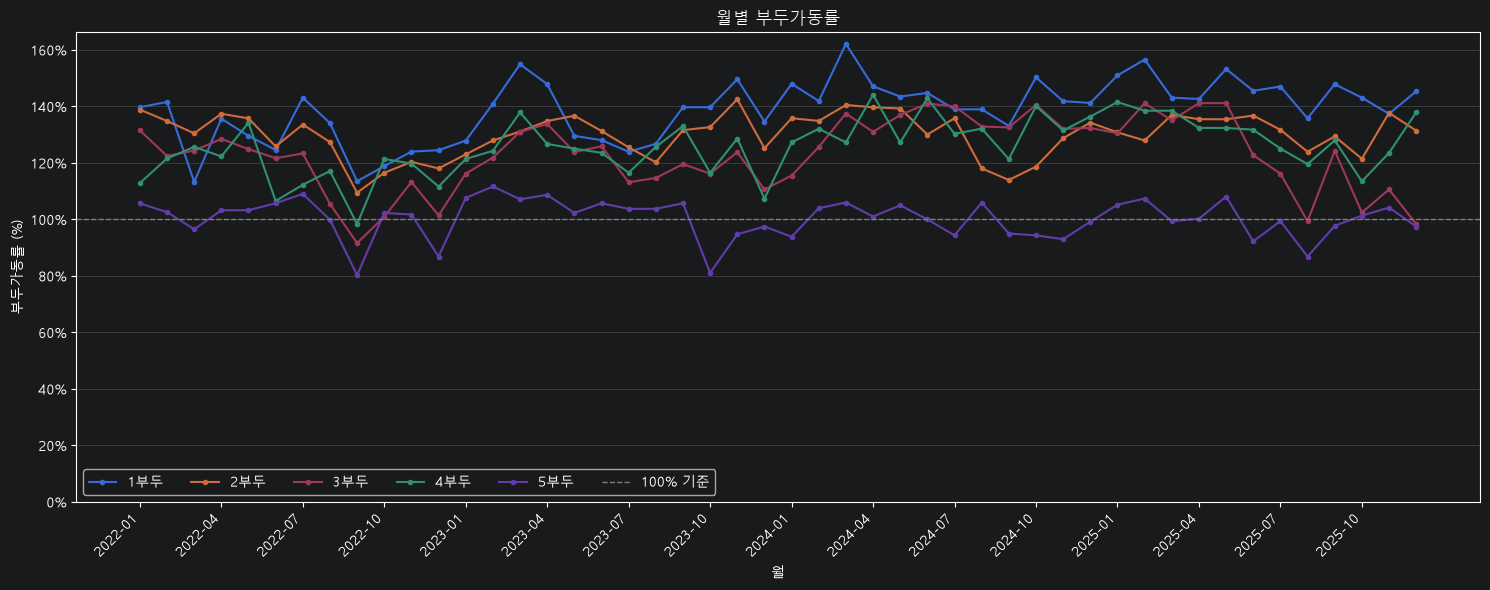

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2022
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 실제 연도별 하역능력을 확보하면 수정하세요.
reference_capacity = {
    "1부두": 2_090_000,
    "2부두": 3_790_000,
    "3부두": 2_310_000,
    "4부두": 1_930_000,
    "5부두": 2_440_000
}

# 참고값을 2022~2025년 동일하게 적용하는 가정
capacity_by_year = {
    year: reference_capacity.copy()
    for year in range(START_YEAR, END_YEAR + 1)
}

# 2. 데이터 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.empty:
    raise ValueError("선택한 기간에 해당하는 자료가 없습니다.")

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

# 3. 부두별 자료를 세로 형태로 변환
monthly = df.melt(
    id_vars=["기준년도", "월"],
    value_vars=[
        "신항1부두",
        "신항2부두",
        "신항3부두",
        "신항4부두",
        "신항5부두"
    ],
    var_name="부두",
    value_name="처리량_천TEU"
)

monthly["부두"] = monthly["부두"].str.replace(
    "신항", "", regex=False
)

monthly["기준월"] = pd.to_datetime({
    "year": monthly["기준년도"],
    "month": monthly["월"],
    "day": 1
})

# 천TEU → TEU
monthly["실제 처리실적(TEU)"] = (
    pd.to_numeric(monthly["처리량_천TEU"], errors="coerce")
    * 1000
)

# 4. 실제 달력 기준 월별·연간 일수
monthly["월 일수"] = monthly["기준월"].dt.days_in_month
monthly["연간 일수"] = (
    monthly["기준월"].dt.is_leap_year
    .map({True: 366, False: 365})
)

monthly["연간 하역능력(TEU)"] = monthly.apply(
    lambda row: capacity_by_year[int(row["기준년도"])][row["부두"]],
    axis=1
)

capacity = monthly["연간 하역능력(TEU)"]

if capacity.isna().any() or capacity.le(0).any():
    raise ValueError("연간 하역능력은 양수로 입력해야 합니다.")

# 5. 월별 환산 하역능력 및 가동률
monthly["월별 환산 하역능력(TEU)"] = (
    monthly["연간 하역능력(TEU)"]
    * monthly["월 일수"]
    / monthly["연간 일수"]
)

monthly["월별 부두가동률(%)"] = (
    monthly["실제 처리실적(TEU)"]
    / monthly["월별 환산 하역능력(TEU)"]
    * 100
)

# 6. 월별·부두별 결과 표
monthly_rate = monthly.pivot(
    index="기준월",
    columns="부두",
    values="월별 부두가동률(%)"
).reindex(columns=list(reference_capacity))

# 누락된 월은 0으로 채우지 않고 결측으로 유지
all_months = pd.date_range(
    f"{START_YEAR}-01-01",
    f"{END_YEAR}-12-01",
    freq="MS"
)

monthly_rate = monthly_rate.reindex(all_months)
monthly_rate.index = monthly_rate.index.strftime("%Y-%m")
monthly_rate.index.name = "월"

print(monthly_rate.round(2).to_string())

# 7. 라인그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(15, 6))

for terminal in monthly_rate.columns:
    ax.plot(
        monthly_rate.index,
        monthly_rate[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal
    )

# 분기 간격: 매년 1·4·7·10월
ticks = list(range(0, len(monthly_rate), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    monthly_rate.index[ticks],
    rotation=45,
    ha="right"
)

ax.set_title("월별 부두가동률")
ax.set_xlabel("월")
ax.set_ylabel("부두가동률 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(bottom=0)

ax.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="100% 기준"
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(ncol=6)

plt.tight_layout()
plt.show()

# 1부두는 신항 1~5부두 중 가장 여유가 없다

           1       2       3       4       5
기준년도                                        
2019  109.81  145.17  120.52  112.28   86.84
2020  131.34  127.63  127.84  109.33   87.38
2021  130.86  134.17  127.32  116.06   94.80
2022  128.47  127.36  115.76  116.99   99.75
2023  136.89  130.18  120.82  123.83  102.38
2024  144.35  130.82  133.20  132.69   99.30
2025  145.65  131.58  121.73  130.16   99.92


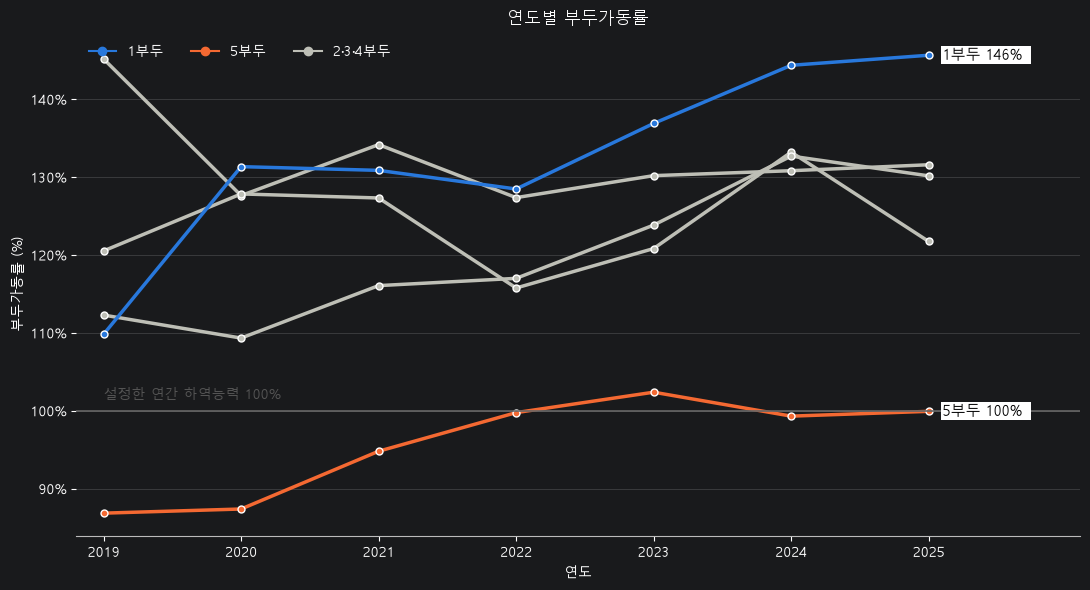

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2019
END_YEAR = 2025

# 연간 하역능력 참고값: TEU/년
# 모든 연도에 동일하게 적용하는 가정
annual_capacity = pd.Series({
    "1": 2_090_000,
    "2": 3_790_000,
    "3": 2_310_000,
    "4": 1_930_000,
    "5": 2_440_000
})

# 2. 월별 처리량 불러오기
df = pd.read_csv(DATA_PATH, encoding="cp949")
df.columns = df.columns.str.strip()

df = df.loc[
    df["기준년도"].between(START_YEAR, END_YEAR)
].copy()

if df.duplicated(["기준년도", "월"]).any():
    raise ValueError("동일 연도·월의 중복 기록이 있습니다.")

if not df["단위"].astype(str).str.strip().eq("천TEU").all():
    raise ValueError("처리량 단위가 천TEU인지 확인하세요.")

years = list(range(START_YEAR, END_YEAR + 1))

month_counts = (
    df.groupby("기준년도")["월"]
    .nunique()
    .reindex(years, fill_value=0)
)

if not month_counts.eq(12).all():
    raise ValueError("12개월 자료가 없는 연도가 있습니다.")

columns = [f"신항{x}부두" for x in annual_capacity.index]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 3. 월별 천TEU → 연간 TEU
annual_teu = (
    df.groupby("기준년도")[columns]
    .sum(min_count=12)
    .reindex(years)
    * 1000
)

if annual_teu.isna().any().any():
    raise ValueError("처리량에 누락된 값이 있습니다.")

annual_teu.columns = annual_capacity.index

# 연간 부두가동률
annual_rate = annual_teu.div(
    annual_capacity, axis="columns"
) * 100

print(annual_rate.round(2).to_string())

# 4. 그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(11, 6))

colors = {
    "1": "#2878DC",
    "2": "#BEBFB6",
    "3": "#BEBFB6",
    "4": "#BEBFB6",
    "5": "#F46932"
}

for terminal in ["2", "3", "4", "5", "1"]:
    ax.plot(
        annual_rate.index,
        annual_rate[terminal],
        color=colors[terminal],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        linewidth=2.5
    )

# 하역능력 100% 기준선
ax.axhline(100, color="#666666", linewidth=1.2)
ax.text(
    START_YEAR,
    101.5,
    "설정한 연간 하역능력 100%",
    fontsize=10,
    color="#555555"
)

# 마지막 연도의 1·5부두 값 표시
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.text(
        END_YEAR + 0.15,
        value,
        f"{terminal}부두 {value:.0f}%",
        va="center",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 범례
handles = [
    Line2D(
        [0], [0], color=colors["1"],
        marker="o", label="1부두"
    ),
    Line2D(
        [0], [0], color=colors["5"],
        marker="o", label="5부두"
    ),
    Line2D(
        [0], [0], color=colors["2"],
        marker="o", label="2·3·4부두"
    )
]

ax.legend(
    handles=handles,
    ncol=3,
    frameon=False,
    loc="upper left"
)

ax.set_title("연도별 부두가동률")
ax.set_xlabel("연도")
ax.set_ylabel("부두가동률 (%)")
ax.set_xticks(years)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("#BBBBBB")

# 마지막 연도 값 표시: 소수점 없이 반올림
for terminal in ["1", "5"]:
    value = annual_rate.loc[END_YEAR, terminal]

    ax.annotate(
        f"{terminal}부두 {value:.0f}%",
        xy=(END_YEAR, value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        color="black",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1
        )
    )

# 오른쪽 글자가 들어갈 공간 확보
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.1)

plt.tight_layout()
plt.show()

# 1부두의 늘어난 재항시간은 늘어난 물량이었다

연간 지표
      연간 처리 TEU  선박 체류시간 합계  시간당 처리 TEU  입항 척수  1척당 처리 TEU
연도                                                        
2022    2685000    21197.30      126.67    708     3792.37
2023    2861000    21843.62      130.98    817     3501.84
2024    3017000    22698.03      132.92    744     4055.11
2025    3044000    22924.20      132.79    659     4619.12

지수 (2022년=100)
      연간 처리 TEU  선박 체류시간 합계  시간당 처리 TEU   입항 척수
연도                                             
2022     100.00      100.00      100.00  100.00
2023     106.55      103.05      103.40  115.40
2024     112.36      107.08      104.94  105.08
2025     113.37      108.15      104.83   93.08


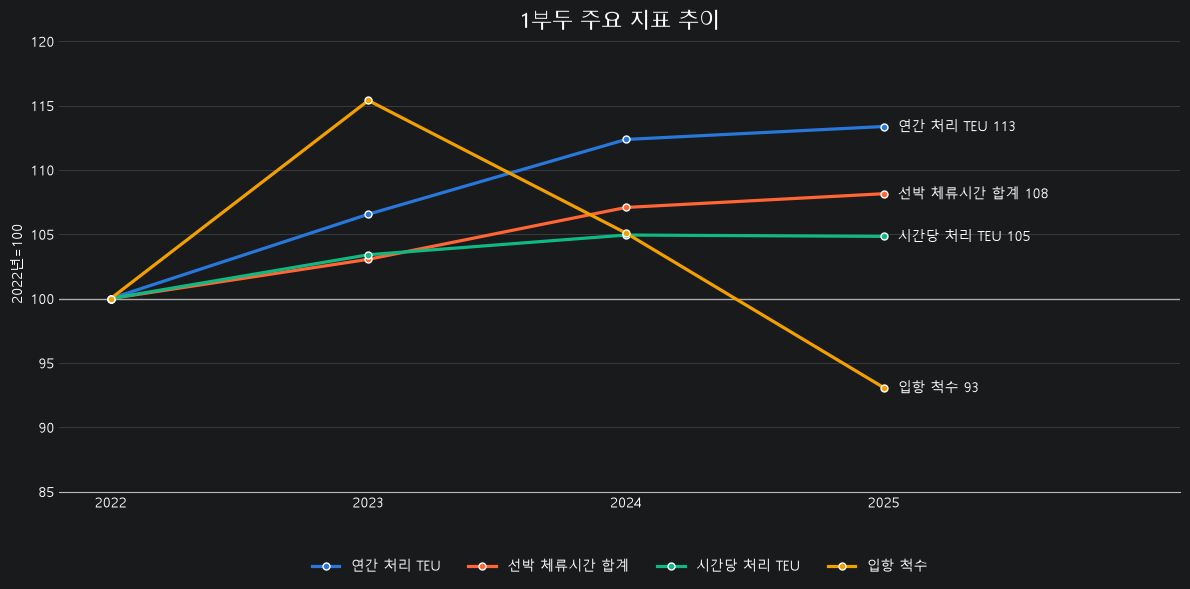

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# ── 1. 설정 ─────────────────────────────────────
RECORD_PATH = r"C:\work\Final_Project\Final_Project\data\record.csv"
PORT_PATH = r"C:\work\Final_Project\Final_Project\data\port_month.csv"

START_YEAR = 2022
END_YEAR = 2025
TERMINAL = "1"

years = list(range(START_YEAR, END_YEAR + 1))

# ── 2. 연간 처리 TEU 계산 ────────────────────────
port = pd.read_csv(PORT_PATH, encoding="cp949")
port.columns = port.columns.str.strip()

port = port.loc[
    port["기준년도"].between(START_YEAR, END_YEAR)
].copy()

# port_month.csv의 단위는 천TEU
teu_column = f"신항{TERMINAL}부두"

annual_teu = (
    port.groupby("기준년도")[teu_column]
    .sum(min_count=12)
    .reindex(years)
    * 1000
)

# ── 3. 입출항 기록 정리 ──────────────────────────
record = pd.read_csv(RECORD_PATH, encoding="utf-8-sig")
record.columns = record.columns.str.strip()

record["부두"] = record["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두",
    expand=False
)

record["입항"] = pd.to_datetime(
    record["입항일시"], errors="coerce"
)
record["출항"] = pd.to_datetime(
    record["출항일시"], errors="coerce"
)

valid = (
    record["부두"].eq(TERMINAL)
    & record["입항"].notna()
    & record["출항"].notna()
    & record["출항"].ge(record["입항"])
)

data = record.loc[valid].copy()

# ── 4. 연간 입항 척수 ────────────────────────────
# 한 행을 입항 한 건으로 집계
# 같은 배가 재방문하면 별도로 계산
annual_calls = (
    data.groupby(data["입항"].dt.year)
    .size()
    .reindex(years, fill_value=0)
)

# ── 5. 연간 선박 체류시간 합계 ───────────────────
# 재항시간 = 출항 - 입항
# 연도를 넘는 기록은 각 연도에 해당하는 시간으로 분할
annual_stay = {}

for year in years:
    start = pd.Timestamp(year=year, month=1, day=1)
    end = pd.Timestamp(year=year + 1, month=1, day=1)

    hours = (
        data["출항"].clip(upper=end)
        - data["입항"].clip(lower=start)
    ).dt.total_seconds().div(3600).clip(lower=0)

    annual_stay[year] = hours.sum()

annual_stay = pd.Series(annual_stay)

# ── 6. 연간 지표 정리 ────────────────────────────
summary = pd.DataFrame(index=years)
summary.index.name = "연도"

summary["연간 처리 TEU"] = annual_teu
summary["선박 체류시간 합계"] = annual_stay

# 전체 처리량 ÷ 선박별 재항시간 합계
summary["시간당 처리 TEU"] = (
    summary["연간 처리 TEU"]
    / summary["선박 체류시간 합계"].replace(0, float("nan"))
)

summary["입항 척수"] = annual_calls

# 참고용: 입항 1회당 처리량
summary["1척당 처리 TEU"] = (
    summary["연간 처리 TEU"]
    / summary["입항 척수"].replace(0, float("nan"))
)

print("연간 지표")
print(summary.round(2).to_string())

# ── 7. 2022년=100으로 지수화 ─────────────────────
graph_columns = [
    "연간 처리 TEU",
    "선박 체류시간 합계",
    "시간당 처리 TEU",
    "입항 척수"
]

base = summary.loc[START_YEAR, graph_columns]

if base.isna().any() or base.le(0).any():
    raise ValueError("기준 연도 지표가 누락되었거나 0 이하입니다.")

index_data = (
    summary[graph_columns]
    .div(base, axis="columns")
    * 100
)

print(f"\n지수 ({START_YEAR}년=100)")
print(index_data.round(2).to_string())

# ── 8. 라인그래프 ────────────────────────────────
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(12, 6))

colors = {
    "연간 처리 TEU": "#2878DC",
    "선박 체류시간 합계": "#FF6535",
    "시간당 처리 TEU": "#10B981",
    "입항 척수": "#F2A000"
}

for column in graph_columns:
    ax.plot(
        index_data.index,
        index_data[column],
        color=colors[column],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        linewidth=2.3,
        label=column
    )

    # 마지막 연도 값 표시
    value = index_data.loc[END_YEAR, column]

    ax.annotate(
        f"{column} {value:.0f}",
        xy=(END_YEAR, value),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10
    )

# 기준 연도 100선
ax.axhline(
    100,
    color="#AAAAAA",
    linewidth=1,
    zorder=0
)

ax.set_title(
    f"{TERMINAL}부두 주요 지표 추이",
    fontsize=15
)
ax.set_ylabel(f"{START_YEAR}년=100")
ax.set_xticks(years)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 1.15)

# 지수이므로 % 기호를 붙이지 않음
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))

ax.set_ylim(
    min(85, index_data.min().min() - 5),
    max(120, index_data.max().max() + 5)
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("#BBBBBB")
ax.tick_params(axis="both", length=0)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

plt.tight_layout()
plt.show()

# 1부두 전체 선석점유율

In [27]:
import pandas as pd

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\record.csv"

start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")  # 종료 시각 미포함
berth_count = 3                  # 1부두 선석 수

# 2. CSV 불러오기
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

# 장소·시각 누락 및 음수 재항시간 제외
valid = (
    df[["부두", "선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
)

# 1부두만 선택
data = df.loc[valid & df["부두"].eq("1")].copy()

# 3. 같은 선석의 직전 선박 확인
# 기간으로 먼저 자르면 이전 선박 기록이 사라질 수 있으므로
# 전체 기록에서 직전 선박을 구한 뒤 계산 기간을 적용
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 추정대기 = max(0, 직전 선박 출항 - 현재 선박 입항)
# 첫 기록은 대기종료 = 입항이므로 추정대기 0
data["대기종료"] = data[["입항", "앞배_출항"]].max(axis=1)

# 4. 분석 기간과 겹치는 시간만 계산
# 연도를 넘는 기록도 기간 안의 시간만 반영
data["기간내_재항시간"] = (
    data["출항"].clip(upper=end)
    - data["입항"].clip(lower=start)
).dt.total_seconds().div(3600).clip(lower=0)

data["기간내_추정대기시간"] = (
    data["대기종료"].clip(upper=end)
    - data["입항"].clip(lower=start)
).dt.total_seconds().div(3600).clip(lower=0)

# 5. 전체 기간 합계 및 점유율
total_stay = data["기간내_재항시간"].sum()
total_wait = data["기간내_추정대기시간"].sum()
total_work = total_stay - total_wait

# 2024년 윤년 자동 반영
period_hours = (end - start).total_seconds() / 3600
available_hours = berth_count * period_hours

occupancy_rate = total_work / available_hours * 100

# 6. 결과 출력
result = pd.DataFrame([{
    "부두": "1부두",
    "분석 기간": "2022~2025년",
    "총 재항시간": total_stay,
    "총 추정대기시간": total_wait,
    "추정 작업시간": total_work,
    "선석 수": berth_count,
    "기간 시간": period_hours,
    "가용 선석시간": available_hours,
    "추정 선석 점유율(%)": occupancy_rate
}])

print(result.round(2).to_string(index=False))
print(f"\n2022~2025년 1부두 추정 선석 점유율: {occupancy_rate:.2f}%")

 부두      분석 기간   총 재항시간  총 추정대기시간  추정 작업시간  선석 수   기간 시간  가용 선석시간  추정 선석 점유율(%)
1부두 2022~2025년 88663.15   5889.05  82774.1     3 35064.0 105192.0         78.69

2022~2025년 1부두 추정 선석 점유율: 78.69%


# 1부두 선석별 선석점유율

2022~2025년 1부두 선석별 누적 추정 점유율
           총 재항시간  총 추정대기시간   추정 작업시간  가용 선석시간  추정 선석 점유율(%)
선석                                                          
1부두 1선석  28682.80   3452.87  25229.93  35064.0         71.95
1부두 2선석  29812.80   1848.92  27963.88  35064.0         79.75
1부두 3선석  30167.55    587.27  29580.28  35064.0         84.36

1부두 전체 추정 점유율: 78.69%


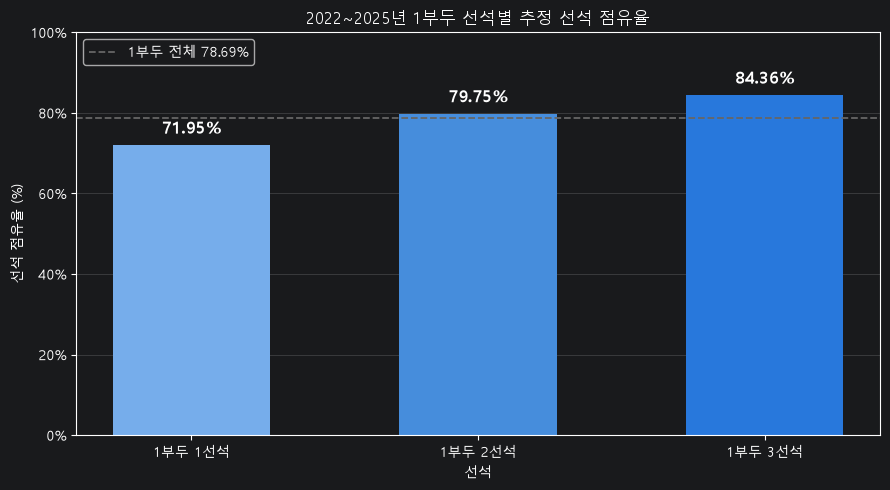

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# 1. 설정
DATA_PATH = r"C:\work\Final_Project\Final_Project\data\record.csv"

start = pd.Timestamp("2022-01-01")
end = pd.Timestamp("2026-01-01")  # 종료 시각 미포함

terminal = "1"
berth_ids = ["1", "2", "3"]
period_hours = (end - start).total_seconds() / 3600

# 2. 데이터 불러오기
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

valid = (
    df["부두"].eq(terminal)
    & df[["선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
)

data = df.loc[valid].copy()

# 3. 전체 기록에서 같은 선석의 직전 선박 확인
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 기존 추정대기 방식 유지
data["대기종료"] = data[["입항", "앞배_출항"]].max(axis=1)

# 4. 분석 기간 내 시간 계산
def hours_in_period(finish):
    return (
        finish.clip(upper=end)
        - data["입항"].clip(lower=start)
    ).dt.total_seconds().div(3600).clip(lower=0)

data["총 재항시간"] = hours_in_period(data["출항"])
data["총 추정대기시간"] = hours_in_period(data["대기종료"])

# 5. 선석별 합계
result = (
    data.groupby("선석")[["총 재항시간", "총 추정대기시간"]]
    .sum()
    .reindex(berth_ids)
)

if result.isna().any().any():
    raise ValueError("일부 선석의 기록이 없습니다. 선석 번호를 확인하세요.")

result["추정 작업시간"] = (
    result["총 재항시간"] - result["총 추정대기시간"]
)

# 선석별 계산이므로 분모에 선석 수 3을 곱하지 않음
result["가용 선석시간"] = period_hours

result["추정 선석 점유율(%)"] = (
    result["추정 작업시간"]
    / result["가용 선석시간"]
    * 100
)

# 1부두 전체 점유율: 전체 선석의 작업시간 / 전체 가용시간
overall_rate = (
    result["추정 작업시간"].sum()
    / (period_hours * len(berth_ids))
    * 100
)

result.index = [
    f"{terminal}부두 {berth}선석"
    for berth in result.index
]
result.index.name = "선석"

print("2022~2025년 1부두 선석별 누적 추정 점유율")
print(result.round(2).to_string())
print(f"\n1부두 전체 추정 점유율: {overall_rate:.2f}%")

# 6. 그래프
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

rates = result["추정 선석 점유율(%)"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    result.index,
    rates,
    color=["#76ADEB", "#468DDC", "#2878DC"],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"{value:.2f}%" for value in rates],
    padding=6,
    fontsize=12,
    fontweight="bold"
)

# 부두 전체 점유율과 비교
ax.axhline(
    overall_rate,
    color="#666666",
    linestyle="--",
    linewidth=1.3,
    label=f"1부두 전체 {overall_rate:.2f}%"
)

ax.set_title("2022~2025년 1부두 선석별 추정 선석 점유율")
ax.set_xlabel("선석")
ax.set_ylabel("선석 점유율 (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_ylim(
    min(0, rates.min() - 10),
    max(100, rates.max() + 10)
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# 1부두 평균재항시간

In [30]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df["부두"] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두",
    expand=False
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df["입항"].ge("2022-01-01")
    & df["입항"].lt("2026-01-01")
    & df["출항"].ge(df["입항"])
].copy()

# 실제 출항까지의 재항시간
data["재항시간"] = (
    data["출항"] - data["입항"]
).dt.total_seconds() / 3600

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 평균 재항시간: {data['재항시간'].mean():.2f}시간")

입항 기록 수: 2,928건
1부두 평균 재항시간: 30.29시간


# 1부두 평균추정대기시간

In [31]:
import pandas as pd

df = pd.read_csv(
    r"C:\work\Final_Project\Final_Project\data\record.csv",
    encoding="utf-8-sig"
)
df.columns = df.columns.str.strip()

df[["부두", "선석"]] = df["계선장소"].str.extract(
    r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석"
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

data = df.loc[
    df["부두"].eq("1")
    & df[["선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
].copy()

# 기간 필터링 전에 같은 선석의 직전 선박 확인
data = data.sort_values(
    ["부두", "선석", "입항"],
    kind="stable"
)

data["앞배_출항"] = (
    data.groupby(["부두", "선석"])["출항"].shift()
)

# 추정대기 = max(0, 직전 선박 출항 - 현재 선박 입항)
data["추정대기시간"] = (
    (data["앞배_출항"] - data["입항"])
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
    .fillna(0)
)

data = data.loc[
    data["입항"].ge("2022-01-01")
    & data["입항"].lt("2026-01-01")
].copy()

print(f"입항 기록 수: {len(data):,}건")
print(f"1부두 총 추정대기시간: {data['추정대기시간'].sum():.2f}시간")
print(f"1부두 평균 추정대기시간: {data['추정대기시간'].mean():.2f}시간")

입항 기록 수: 2,928건
1부두 총 추정대기시간: 5889.05시간
1부두 평균 추정대기시간: 2.01시간


# 부두별 월별 평균추정대기시간

전체 기록: 19,989건
제외 기록: 0건

부두별·월별 평균 추정대기시간 (시간)
부두        1부두   2부두   3부두   4부두    5부두
월                                     
2022-01  2.42  1.58  3.74  3.94   5.41
2022-02  0.98  3.34  6.41  6.05  12.95
2022-03  0.50  2.53  0.81  5.20   9.36
2022-04  1.55  3.37  2.57  4.91   7.94
2022-05  2.42  2.25  4.08  6.95   9.25
2022-06  1.13  1.60  3.95  1.74   5.68
2022-07  0.36  2.89  2.44  2.35   4.34
2022-08  0.66  2.31  0.48  2.09   3.88
2022-09  3.51  2.78  0.99  0.69  10.80
2022-10  1.01  0.72  0.51  0.71  11.75
2022-11  0.51  1.29  0.82  0.29   4.40
2022-12  1.47  0.86  0.96  0.44   4.63
2023-01  0.22  1.81  1.26  1.01   4.52
2023-02  0.00  3.08  1.33  2.26   6.12
2023-03  1.93  1.80  3.17  0.38   0.79
2023-04  2.12  2.29  1.71  1.19   1.30
2023-05  0.86  4.71  2.11  2.06   3.92
2023-06  3.06  4.68  1.69  2.19   2.38
2023-07  3.42  3.47  1.17  1.47   4.27
2023-08  0.81  4.85  0.80  2.68   2.04
2023-09  4.87  4.52  3.15  2.65   7.56
2023-10  5.91  1.84  0.92  2.82   0.38
2023-11  3.57  4

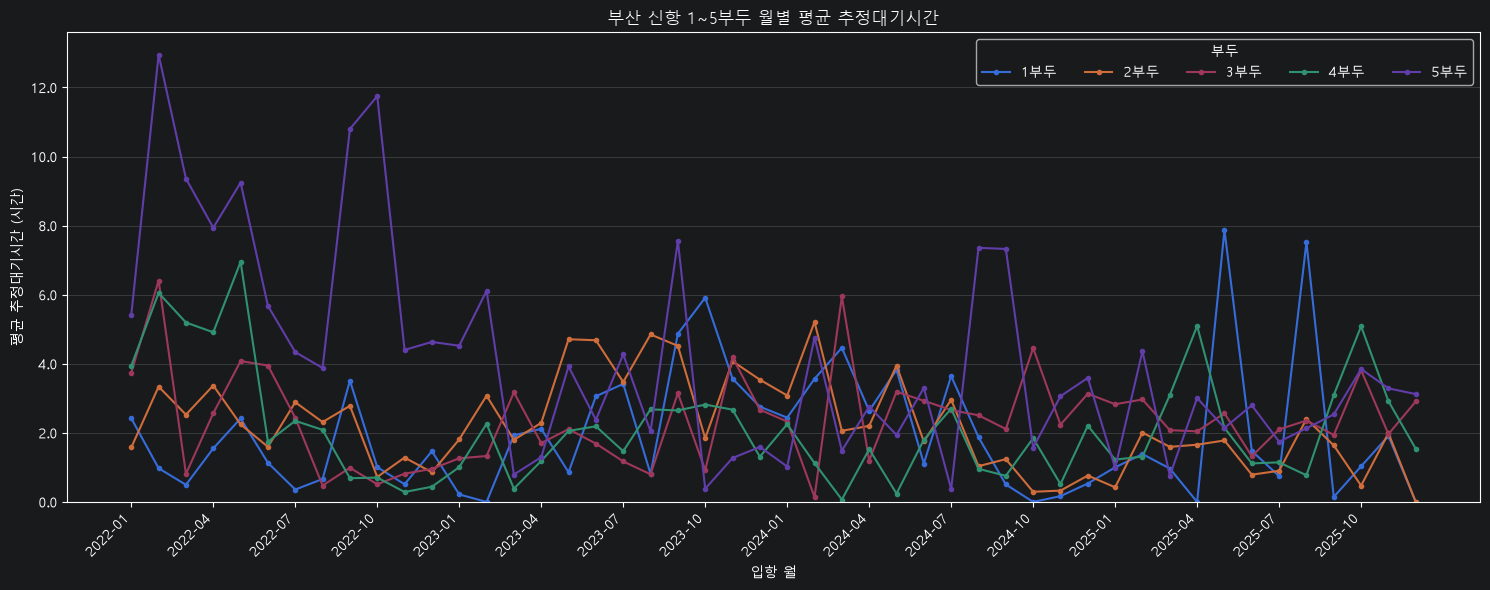

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# ── 1. 설정 ─────────────────────────────────────
DATA_PATH = Path(r"C:\work\Final_Project\data\record.csv")
OUTPUT_DIR = DATA_PATH.parent

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")  # 2025-12-31까지 포함

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ── 2. CSV 불러오기 및 전처리 ────────────────────
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

# 예: '신항 1부두 2선석' → 부두='1', 선석='2'
df[["부두", "선석"]] = (
    df["계선장소"]
    .astype("string")
    .str.extract(r"신항\s*([1-5])\s*부두\s*(\d+)\s*선석")
)

df["입항"] = pd.to_datetime(df["입항일시"], errors="coerce")
df["출항"] = pd.to_datetime(df["출항일시"], errors="coerce")

# 부두·선석·일시 누락, 또는 출항이 입항보다 빠른 데이터 제외
valid = (
    df[["부두", "선석", "입항", "출항"]].notna().all(axis=1)
    & df["출항"].ge(df["입항"])
)

print(f"전체 기록: {len(df):,}건")
print(f"제외 기록: {(~valid).sum():,}건")

df = df.loc[valid].copy()

# ── 3. 선박별 추정대기시간 계산 ──────────────────
# 같은 부두·선석에서 입항 순서로 정렬
df = df.sort_values(["부두", "선석", "입항"], kind="stable")

# 입항 순서상 직전 선박의 출항 시각
df["앞배_출항"] = df.groupby(["부두", "선석"])["출항"].shift()

# 추정대기시간:
# 직전 선박 출항 시각 - 현재 선박 입항 시각
# 음수(겹치지 않음)와 해당 선석의 첫 선박은 0시간 처리
df["추정대기"] = (
    (df["앞배_출항"] - df["입항"])
    .dt.total_seconds()
    .div(3600)
    .clip(lower=0)
    .fillna(0)
)

# ── 4. 부두별·월별 평균 추정대기시간 ─────────────
# 입항 월 기준: 해당 월에 입항한 선박들의 추정대기 평균
period_df = df.loc[
    df["입항"].ge(START) & df["입항"].lt(END)
].copy()

period_df["월"] = period_df["입항"].dt.to_period("M")

monthly_avg = (
    period_df.groupby(["월", "부두"], observed=True)
    .agg(
        평균추정대기시간_시간=("추정대기", "mean"),
        선박수=("추정대기", "size"),
    )
    .reset_index()
)

# 월별·부두별 피벗 테이블 생성
all_months = pd.period_range(
    START,
    END - pd.Timedelta(days=1),
    freq="M",
)

result = (
    monthly_avg.pivot(
        index="월",
        columns="부두",
        values="평균추정대기시간_시간",
    )
    .reindex(index=all_months, columns=list("12345"))
)

result.index = result.index.astype(str)
result.index.name = "월"
result.columns = result.columns + "부두"

print("\n부두별·월별 평균 추정대기시간 (시간)")
print(result.round(2).to_string())

print("\n분석 기간 내 부두별 평균 추정대기시간 (시간)")
overall_avg = (
    period_df.groupby("부두")["추정대기"]
    .mean()
    .reindex(list("12345"))
)
overall_avg.index = overall_avg.index + "부두"
print(overall_avg.round(2).to_string())

# CSV 저장
result.round(2).to_csv(
    OUTPUT_DIR / "부두별_월별_평균추정대기시간.csv",
    encoding="utf-8-sig",
)

# ── 5. 라인 그래프 ───────────────────────────────
fig, ax = plt.subplots(figsize=(15, 6))

for terminal in result.columns:
    ax.plot(
        result.index,
        result[terminal],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=terminal,
    )

ax.set_title("부산 신항 1~5부두 월별 평균 추정대기시간")
ax.set_xlabel("입항 월")
ax.set_ylabel("평균 추정대기시간 (시간)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.1f}"))
ax.set_ylim(bottom=0)

# 분기별로 표시: 매년 1·4·7·10월
ticks = list(range(0, len(result), 3))
ax.set_xticks(ticks)
ax.set_xticklabels(
    result.index[ticks],
    rotation=45,
    ha="right",
)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="부두", ncol=5)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "부두별_월별_평균추정대기시간_라인그래프.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()